# 응용 07. Optimizer·Dropout 비교와 최적 모델 복원

2026-10-30 실습 기록 · 원본: `../07_project.py`


## 0. 준비와 목적
pandas와 IPython이 설치된 커널에서 위에서 아래로 실행합니다. 이 노트북은 저장된 결과 CSV·PNG를 읽어 분석하므로 학습을 재실행하거나 결과 파일을 덮어쓰지 않습니다. 원본 학습 실행에는 PyTorch·Matplotlib도 필요합니다.

실습 목표는 Optimizer와 Dropout 비교, 최소 valid loss 모델의 복원, 클래스별 Recall 계산, 검증 표본별 예측 저장입니다. test는 학습·설정 선택에 사용하지 않습니다.

## 1. 비교 조건
| 후보 | Optimizer | Dropout p | lr |
| --- | --- | ---: | ---: |
| sgd | SGD(momentum=0) | 0 | 0.01 |
| adamw | AdamW | 0 | 0.01 |
| adamw_dropout | AdamW | 0.3 | 0.01 |

SGD와 AdamW를 비교할 때는 Dropout을 0으로 고정하고, Dropout 효과는 두 AdamW 후보끼리 비교합니다. 공통 학습률이 각 Optimizer의 최적 학습률이라는 뜻은 아닙니다.

공통 조건: 입력 2 → 은닉 32 → 은닉 32 → 출력 2, ReLU, BN 없음, weight_decay=0, batch_size=32, 40·80·120 epochs 각각, 모델 seed=42, shuffle seed=43. 후보마다 모델·Optimizer·DataLoader를 새로 만듭니다. train 240건, valid 80건이며 마지막 학습 batch는 16건입니다. 원본은 CUDA 사용 가능 여부에 따라 장치를 선택합니다.

### 종료 epoch별 실행과 저장
`python 07_project.py`를 실행하면 40·80·120 epoch를 각 후보마다 처음부터 새로 학습합니다. 이전 모델의 학습을 이어받지 않습니다. 각 결과는 `outputs/07_40`, `outputs/07_80`, `outputs/07_120` 폴더에 저장하고 전체 9개 후보의 비교는 `outputs/07_epoch_comparison.csv`에 저장합니다. 기존 outputs 바로 아래의 40 epoch 결과는 보존합니다.

이번 재실행은 CPU에서 진행했습니다. 기존 40 epoch 기록의 Dropout 후보 최소 손실은 0.036936이었고 이번 재실행은 0.033904입니다. 기존 결과를 지우지 않았으며 아래 표는 **이번 재실행 결과**를 사용합니다. 이전 실행 환경이 완전히 같았는지는 확인하지 않았으므로 차이의 원인은 단정하지 않습니다.


In [1]:
from pathlib import Path
import pandas as pd

candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / "20261030" / "02_응용"]
base = next((p for p in candidates if (p / "07_project.py").is_file()), None)
if base is None:
    raise FileNotFoundError("저장소 루트, 02_응용 또는 docs에서 실행하세요.")
base = base.resolve()
out = base / "outputs"
summary = pd.read_csv(out / "07_epoch_comparison.csv")


In [2]:
print("=== 40 epochs 결과표 ===")
print(summary.loc[summary["epochs"] == 40,
      ["name", "best_epoch", "best_valid_loss", "valid_acc_at_best",
       "last_valid_loss", "restored_valid_loss", "restored_matches_best"]]
      .to_string(index=False, float_format=lambda x: f"{x:.6f}"))


=== 40 epochs 결과표 ===
         name  best_epoch  best_valid_loss  valid_acc_at_best  last_valid_loss  restored_valid_loss  restored_matches_best
          sgd          40         0.428053           0.800000         0.428053             0.428053                   True
        adamw          38         0.016560           1.000000         0.020212             0.016560                   True
adamw_dropout          40         0.033904           0.987500         0.033904             0.033904                   True


In [3]:
print("=== 80 epochs 결과표 ===")
print(summary.loc[summary["epochs"] == 80,
      ["name", "best_epoch", "best_valid_loss", "valid_acc_at_best",
       "last_valid_loss", "restored_valid_loss", "restored_matches_best"]]
      .to_string(index=False, float_format=lambda x: f"{x:.6f}"))


=== 80 epochs 결과표 ===
         name  best_epoch  best_valid_loss  valid_acc_at_best  last_valid_loss  restored_valid_loss  restored_matches_best
          sgd          80         0.350138           0.825000         0.350138             0.350138                   True
        adamw          78         0.006114           1.000000         0.036195             0.006114                   True
adamw_dropout          76         0.019034           0.987500         0.037689             0.019034                   True


In [4]:
print("=== 120 epochs 결과표 ===")
print(summary.loc[summary["epochs"] == 120,
      ["name", "best_epoch", "best_valid_loss", "valid_acc_at_best",
       "last_valid_loss", "restored_valid_loss", "restored_matches_best"]]
      .to_string(index=False, float_format=lambda x: f"{x:.6f}"))


=== 120 epochs 결과표 ===
         name  best_epoch  best_valid_loss  valid_acc_at_best  last_valid_loss  restored_valid_loss  restored_matches_best
          sgd         119         0.322713           0.862500         0.322803             0.322713                   True
        adamw         107         0.004557           1.000000         0.008291             0.004557                   True
adamw_dropout         109         0.016552           1.000000         0.023662             0.016552                   True


## 2. A07·A08: 학습과 평가
학습 batch마다 `optimizer.zero_grad()` → forward와 loss 계산 → `loss.backward()` → `optimizer.step()` 순서로 수행합니다. 이전 기울기를 비우고 현재 loss의 기울기로 한 번 갱신합니다.

각 epoch 학습 전 `model.train()`으로 Dropout을 활성화하고, epoch 종료 후 `model.eval()`과 `torch.no_grad()`로 train·valid 손실을 평가합니다. `eval()`은 모듈의 동작 모드, `no_grad()`는 연산의 기울기 기록을 제어합니다.

`train_loss_eval`은 학습 중 Dropout을 적용한 batch 손실이 아니라, epoch 말 Dropout을 끈 모델이 train 자료에서 얻은 손실입니다. valid는 가중치 갱신에 사용하지 않고 모델 선택에 사용합니다.


## 3. A09: best 모델을 독립적으로 보관하고 복원
초깃값은 `best_loss=float("inf")`, `best_epoch=0`, `best_state=None`입니다. 각 epoch의 검증 손실이 기존 최솟값보다 낮을 때만 세 값을 함께 갱신합니다.

원본에 기록한 설명:

```python
# 해설 A09: 현재 모델의 검증 손실이 지금까지의 최솟값보다 낮을 때만 세 값을 함께 갱신합니다.
# valid 데이터는 모델 선택에 사용하며, 이 블록에서 역전파나 가중치 학습을 수행하지 않습니다.
if valid_loss < best_loss:  # 엄격한 < 비교이므로 손실이 같으면 먼저 발견한 epoch를 유지합니다.
    best_loss = valid_loss  # 새 최소 검증 손실을 저장해 다음 epoch의 비교 기준으로 사용합니다.
    best_epoch = epoch  # 최소 손실을 기록한 현재 epoch 번호도 함께 보관합니다.
    # state_dict()에는 가중치·편향 등 파라미터와 BN running 통계 같은 버퍼가 들어갑니다.
    # state_dict()만 대입하면 내부 Tensor가 현재 모델과 저장소를 공유할 수 있어,
    # 이후 optimizer.step() 등으로 모델이 바뀔 때 보관한 최적 상태도 바뀔 수 있습니다.
    best_state = copy.deepcopy(model.state_dict())  # Tensor까지 독립적으로 복사해 이 시점의 상태를 고정합니다.
    # 학습 종료 후 model.load_state_dict(best_state)로 이 상태를 복원합니다.
    # 메모리에 보관하는 복사본이며, 모델 파일로 저장하려면 별도의 torch.save()가 필요합니다.
```

`<`를 사용하므로 동률이면 앞 epoch를 유지합니다. `state_dict()`에는 가중치·편향과 버퍼가 들어가며, `deepcopy`는 이후 학습의 변경을 받지 않는 독립 상태를 만듭니다.

학습 종료 후 `model.load_state_dict(best_state)`로 복원하고 `eval()`로 예측합니다. `restored_valid_loss`와 `best_loss`의 차이가 1e-6 미만인지 `restored_matches_best`로 기록합니다. **표에서 best epoch를 찾는 것만으로는 최적 가중치가 복원되지 않습니다.**

현재 모델 상태는 메모리에 보관하며 별도 `.pt` 모델 파일은 저장하지 않습니다. CSV·PNG 저장과 모델 가중치 파일 저장은 다릅니다. 각 설정의 전체 40·80·120 epochs를 수행하므로 Early Stopping도 아닙니다.


## 4. 40·80·120 epoch 실제 비교 결과

| epochs | 후보 | best epoch | best valid loss | best valid accuracy | 마지막 valid loss |
| ---: | --- | ---: | ---: | ---: | ---: |
| 40 | sgd | 40 | 0.428053 | 80.00% | 0.428053 |
| 40 | adamw | 38 | 0.016560 | 100.00% | 0.020212 |
| 40 | adamw_dropout | 40 | 0.033904 | 98.75% | 0.033904 |
| 80 | sgd | 80 | 0.350138 | 82.50% | 0.350138 |
| 80 | adamw | 78 | 0.006114 | 100.00% | 0.036195 |
| 80 | adamw_dropout | 76 | 0.019034 | 98.75% | 0.037689 |
| 120 | sgd | 119 | 0.322713 | 86.25% | 0.322803 |
| 120 | adamw | 107 | 0.004557 | 100.00% | 0.008291 |
| 120 | adamw_dropout | 109 | 0.016552 | 100.00% | 0.023662 |

각 종료 시점의 `07_comparison.csv`와 후보별 history가 근거입니다. 세 종료 시점 모두 기본 AdamW가 가장 낮은 best valid loss를 기록했습니다. SGD는 종료 시점이 늘면서 0.428053→0.350138→0.322713, AdamW는 0.016560→0.006114→0.004557, Dropout 후보는 0.033904→0.019034→0.016552로 최소 손실이 낮아졌습니다.

관찰할 epoch 후보가 늘면 누적 최소값은 더 작아지거나 유지됩니다. 이 사실만으로 긴 학습의 마지막 모델이 항상 좋다고 해석할 수 없습니다. 후보마다 최적 epoch를 복원해서 평가하며, test는 선택에 사용하지 않습니다. 단일 seed·작은 데이터·공통 학습률 결과를 일반적인 성능 순위로 해석하지 않습니다.

### best 이후 변화와 과적합 가능성

| epochs | 후보 | best train loss | 마지막 train loss | best valid loss | 마지막 valid loss |
| ---: | --- | ---: | ---: | ---: | ---: |
| 40 | sgd | 0.396183 | 0.396183 | 0.428053 | 0.428053 |
| 40 | adamw | 0.018079 | 0.016876 | 0.016560 | 0.020212 |
| 40 | adamw_dropout | 0.033884 | 0.033884 | 0.033904 | 0.033904 |
| 80 | sgd | 0.307824 | 0.307824 | 0.350138 | 0.350138 |
| 80 | adamw | 0.016391 | 0.079643 | 0.006114 | 0.036195 |
| 80 | adamw_dropout | 0.022339 | 0.032145 | 0.019034 | 0.037689 |
| 120 | sgd | 0.281177 | 0.280752 | 0.322713 | 0.322803 |
| 120 | adamw | 0.011569 | 0.005866 | 0.004557 | 0.008291 |
| 120 | adamw_dropout | 0.014073 | 0.020985 | 0.016552 | 0.023662 |

best와 마지막 지점의 train 손실이 줄고 valid 손실이 증가하면 과적합 가능성과 일치합니다. 둘 다 증가하는 경우에는 학습 변동·최적화 불안정 가능성도 봅니다. 마지막 epoch가 best인 경우에는 best 이후를 관찰하지 못한 상태입니다. 이 표는 양 끝점 비교이므로 중간 epoch가 단조롭게 변했다는 뜻은 아니며, 아래 그래프와 함께 확인해야 합니다.


## 5. A10: 클래스별 support·correct·Recall
| 변수 | 계산과 의미 |
| --- | --- |
| labels | valid의 실제 정답을 CPU로 이동 |
| best_pred | 복원한 모델의 logits에서 argmax로 선택한 예측 클래스, CPU로 이동 |
| mask | `labels == label`: 실제 정답이 현재 클래스인 위치 |
| support | mask의 True 개수: 해당 클래스의 실제 표본 수 |
| correct | mask로 선택한 표본 중 예측도 현재 클래스인 개수 |
| recall | correct / support, support가 0이면 None |
| class_rows | 각 클래스의 label·support·correct·recall을 담은 딕셔너리 목록 |

`for label in (0, 1)`로 클래스마다 한 번만 계산합니다. `for label in labels`는 표본마다 반복해 클래스 결과가 중복됩니다. `label`만 append하면 지표가 저장되지 않으므로 결과 딕셔너리를 append합니다.

```python
mask = labels == label  # 실제 정답이 현재 클래스인 위치
support = mask.sum().item()  # 해당 표본 수를 Python 숫자로 변환
correct = (best_pred[mask] == label).sum().item()  # 그중 예측까지 맞힌 수
recall = correct / support if support > 0 else None  # 실제 표본 중 맞힌 비율
class_rows.append({"label": label, "support": support,
                   "correct": correct, "recall": recall})
```

Recall의 분모는 **해당 클래스의 실제 표본 수**입니다. 예측이 해당 클래스인 표본 수를 분모로 쓰면 Precision이며, 전체 표본 수를 쓰면 클래스별 Recall이 아닙니다.


In [5]:
metric_tables = []
for result in summary.itertuples():
    metrics = pd.read_csv(out / f"07_{result.epochs}" / f"07_{result.name}_class_metrics.csv")
    metrics.insert(0, "name", result.name)
    metrics.insert(0, "epochs", result.epochs)
    metric_tables.append(metrics)
print(pd.concat(metric_tables, ignore_index=True).to_string(index=False))


 epochs          name  label  support  correct  recall
     40           sgd      0       40       32   0.800
     40           sgd      1       40       32   0.800
     40         adamw      0       40       40   1.000
     40         adamw      1       40       40   1.000
     40 adamw_dropout      0       40       39   0.975
     40 adamw_dropout      1       40       40   1.000
     80           sgd      0       40       35   0.875
     80           sgd      1       40       31   0.775
     80         adamw      0       40       40   1.000
     80         adamw      1       40       40   1.000
     80 adamw_dropout      0       40       39   0.975
     80 adamw_dropout      1       40       40   1.000
    120           sgd      0       40       36   0.900
    120           sgd      1       40       33   0.825
    120         adamw      0       40       40   1.000
    120         adamw      1       40       40   1.000
    120 adamw_dropout      0       40       40   1.000
    120 ad

## 6. 표본별 예측 저장과 결과 검증
`07_{후보}_predictions.csv`에는 검증 표본마다 `id`(표본 식별자), `actual`(실제 정답), `predicted`(복원한 best 모델의 예측 클래스)를 기록합니다. 실제 요청 로그가 아닌 검증 자료의 표본별 예측입니다. 확률이나 logits는 현재 CSV에 저장하지 않습니다.

아래는 후보별 80건 여부, 예측에서 다시 계산한 클래스별 지표, history의 최소 손실과 복원 손실의 일치를 확인합니다.


In [6]:
for result in summary.itertuples():
    run_out = out / f"07_{result.epochs}"
    predictions = pd.read_csv(run_out / f"07_{result.name}_predictions.csv")
    metrics = pd.read_csv(run_out / f"07_{result.name}_class_metrics.csv")
    history = pd.read_csv(run_out / f"07_{result.name}_history.csv")
    assert history["epoch"].tolist() == list(range(1, result.epochs + 1))
    assert len(predictions) == 80
    assert abs(history["valid_loss"].min() - result.restored_valid_loss) < 1e-6
    assert result.best_epoch == history.loc[history["valid_loss"].idxmin(), "epoch"]
    assert result.restored_matches_best
    for row in metrics.itertuples():
        selected = predictions[predictions["actual"] == row.label]
        assert len(selected) == row.support
        assert (selected["actual"] == selected["predicted"]).sum() == row.correct
        if row.support:
            assert abs(row.recall - row.correct / row.support) < 1e-8
        else:
            assert pd.isna(row.recall)
    assert abs((predictions["actual"] == predictions["predicted"]).mean()
               - result.valid_acc_at_best) < 1e-6
    print(f"{result.epochs} epochs / {result.name}: best 복원·예측 80건·Recall 일치 확인")
    print(predictions.head().to_string(index=False))


40 epochs / sgd: best 복원·예측 80건·Recall 일치 확인
      id  actual  predicted
D10_0354       1          1
D10_0146       0          0
D10_0122       0          0
D10_0333       1          1
D10_0123       0          0
40 epochs / adamw: best 복원·예측 80건·Recall 일치 확인
      id  actual  predicted
D10_0354       1          1
D10_0146       0          0
D10_0122       0          0
D10_0333       1          1
D10_0123       0          0
40 epochs / adamw_dropout: best 복원·예측 80건·Recall 일치 확인
      id  actual  predicted
D10_0354       1          1
D10_0146       0          0
D10_0122       0          0
D10_0333       1          1
D10_0123       0          0
80 epochs / sgd: best 복원·예측 80건·Recall 일치 확인
      id  actual  predicted
D10_0354       1          1
D10_0146       0          0
D10_0122       0          0
D10_0333       1          1
D10_0123       0          0
80 epochs / adamw: best 복원·예측 80건·Recall 일치 확인
      id  actual  predicted
D10_0354       1          1
D10_0146       0          0
D10_0

## 7. 40·80·120 epoch별 후보 학습곡선

각 종료 시점의 SGD·AdamW·AdamW+Dropout 그래프 총 9개를 표시합니다. 실선은 epoch 말 eval 모드의 train·valid 손실, 점선은 해당 실행의 best epoch입니다. 그림별 축 범위와 표의 실제 수치를 함께 비교합니다.


40 epochs / sgd


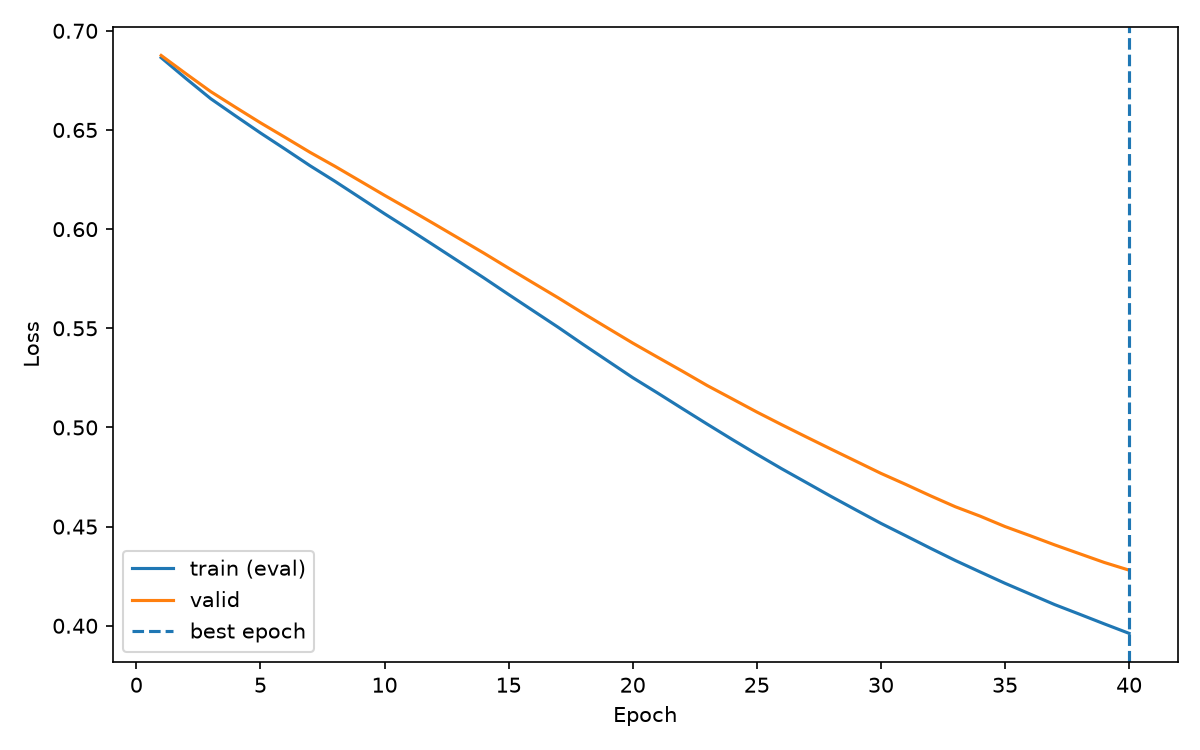

40 epochs / adamw


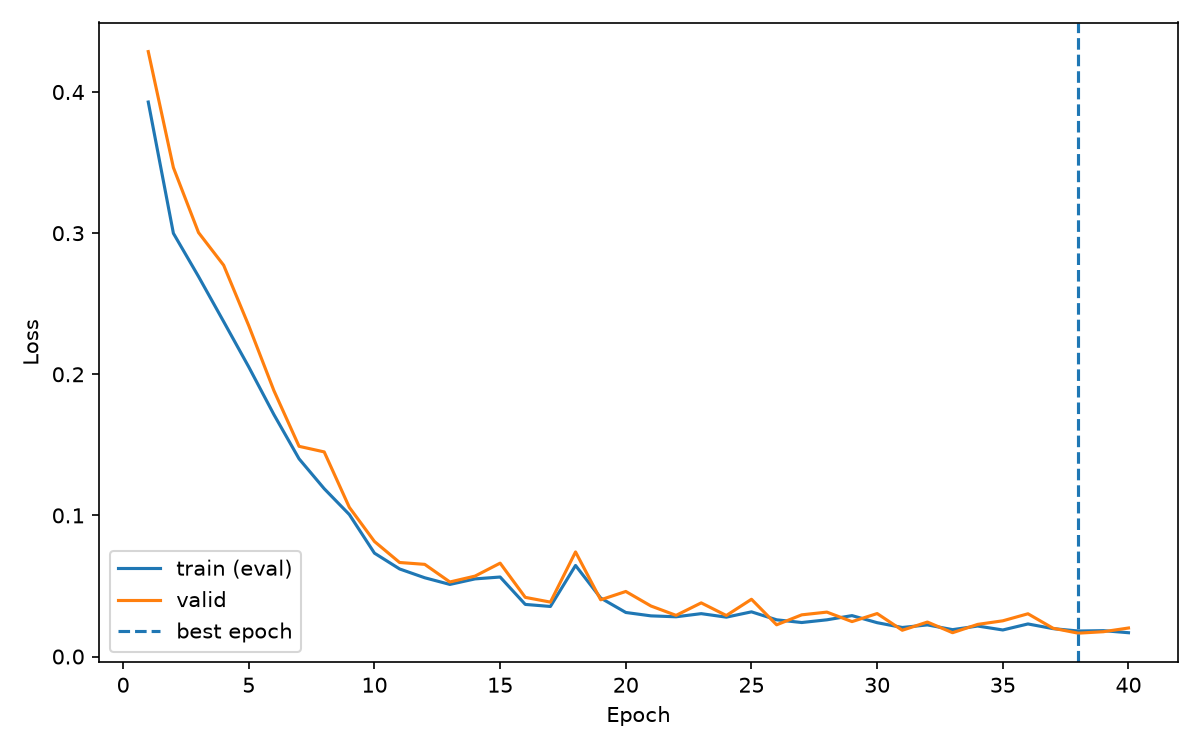

40 epochs / adamw_dropout


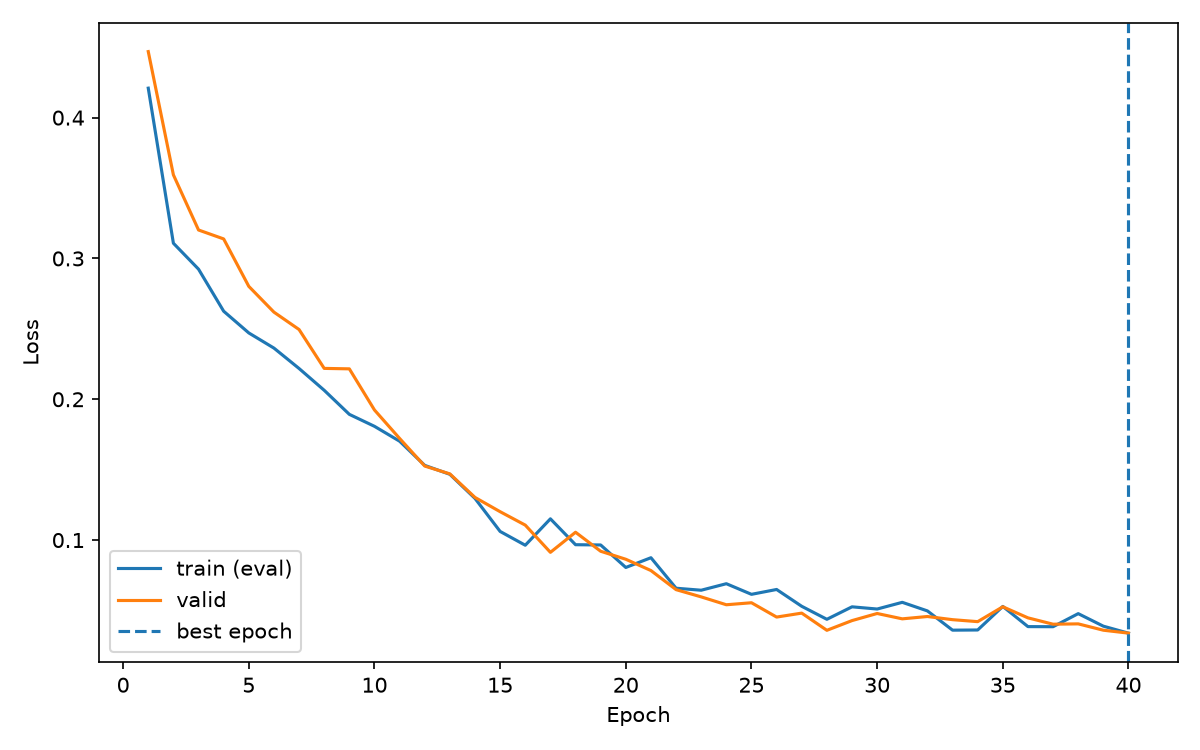

80 epochs / sgd


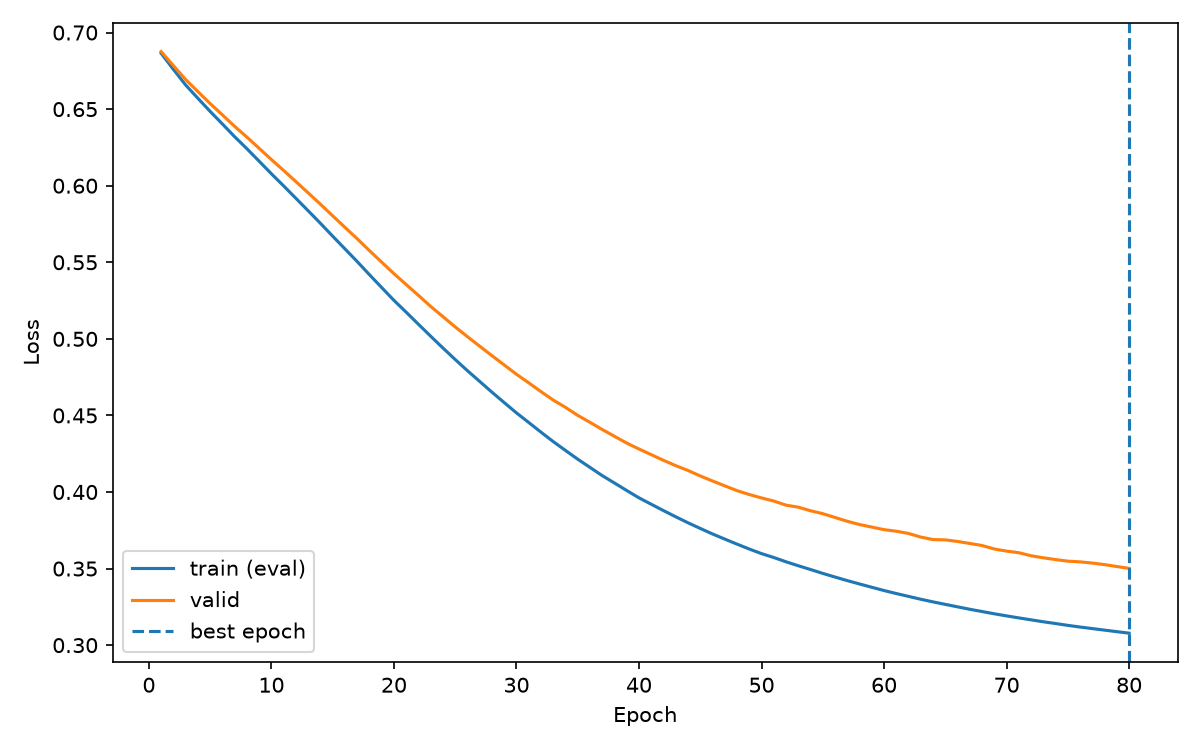

80 epochs / adamw


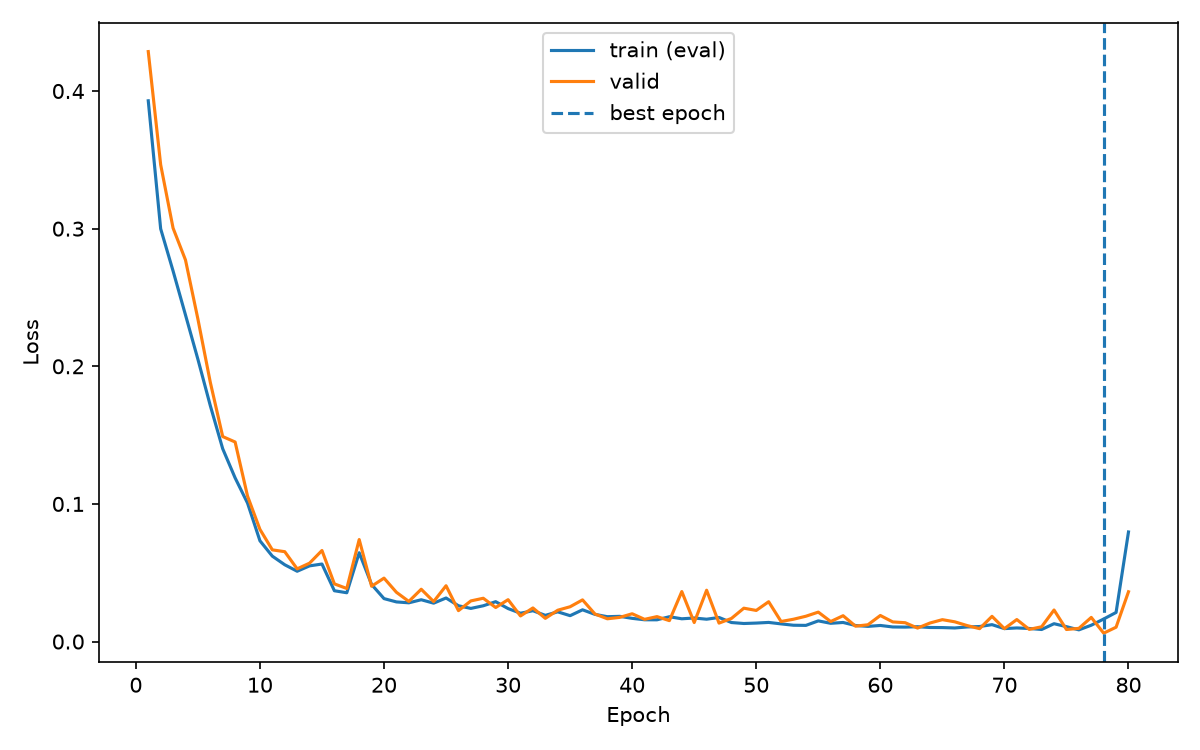

80 epochs / adamw_dropout


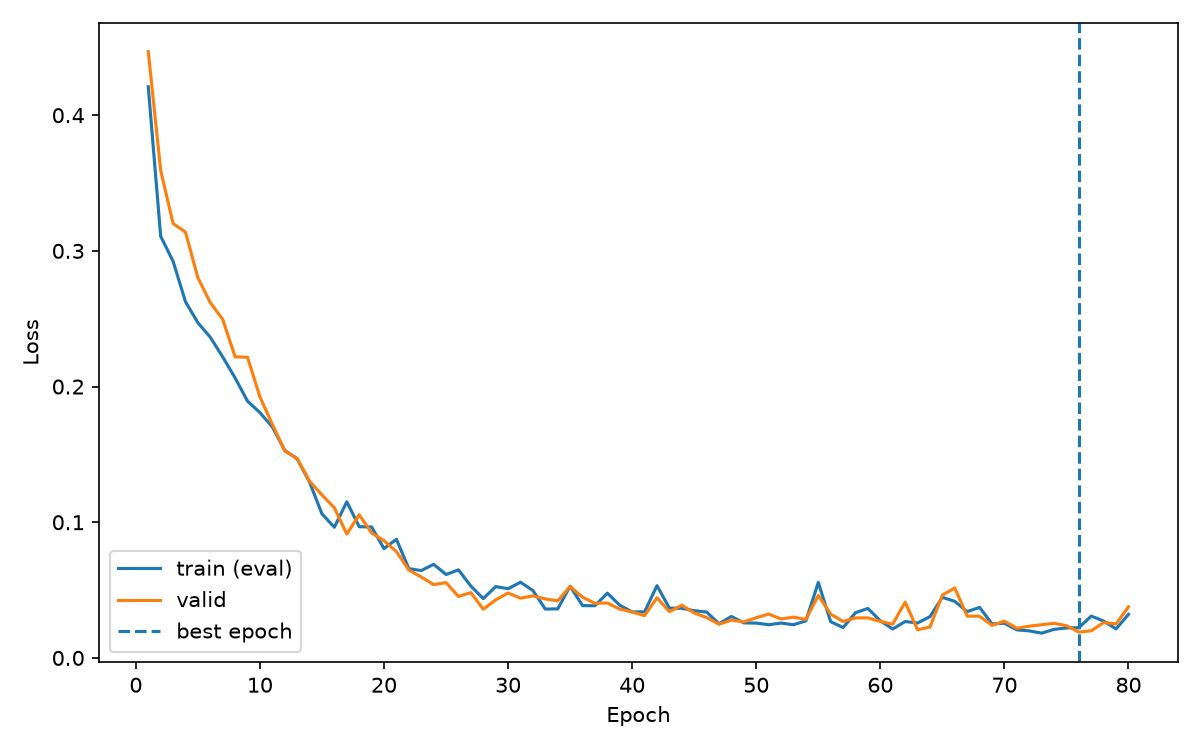

120 epochs / sgd


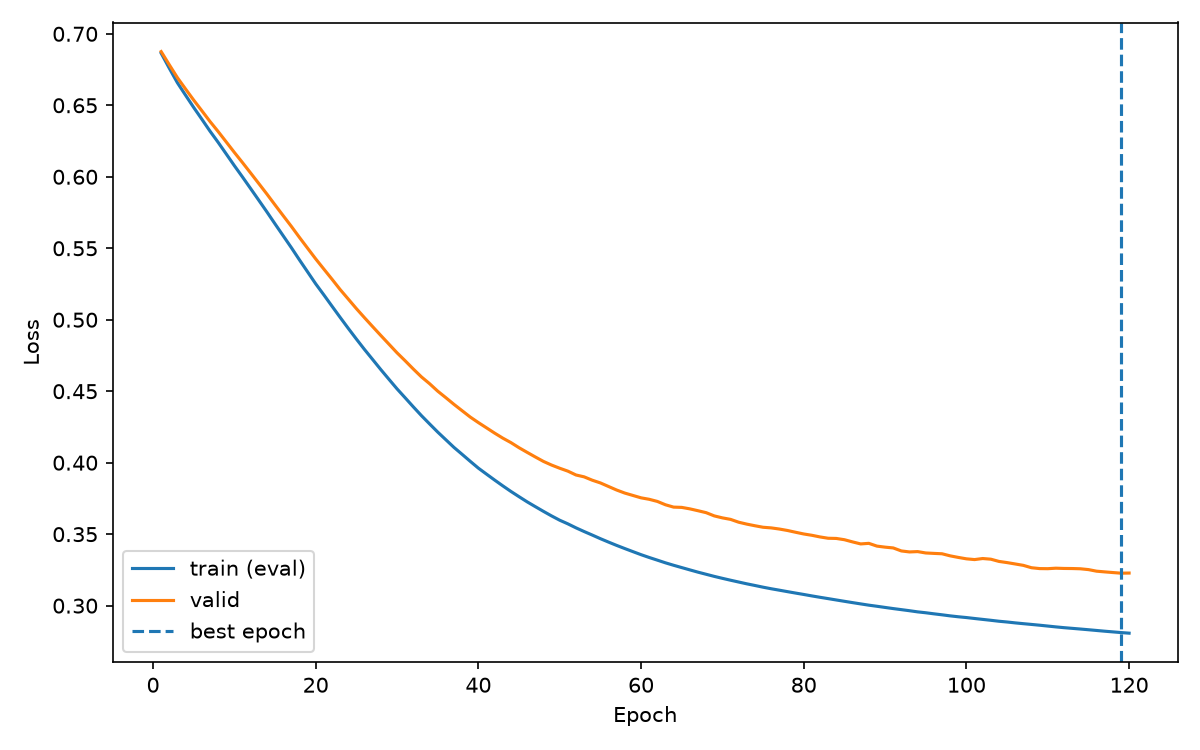

120 epochs / adamw


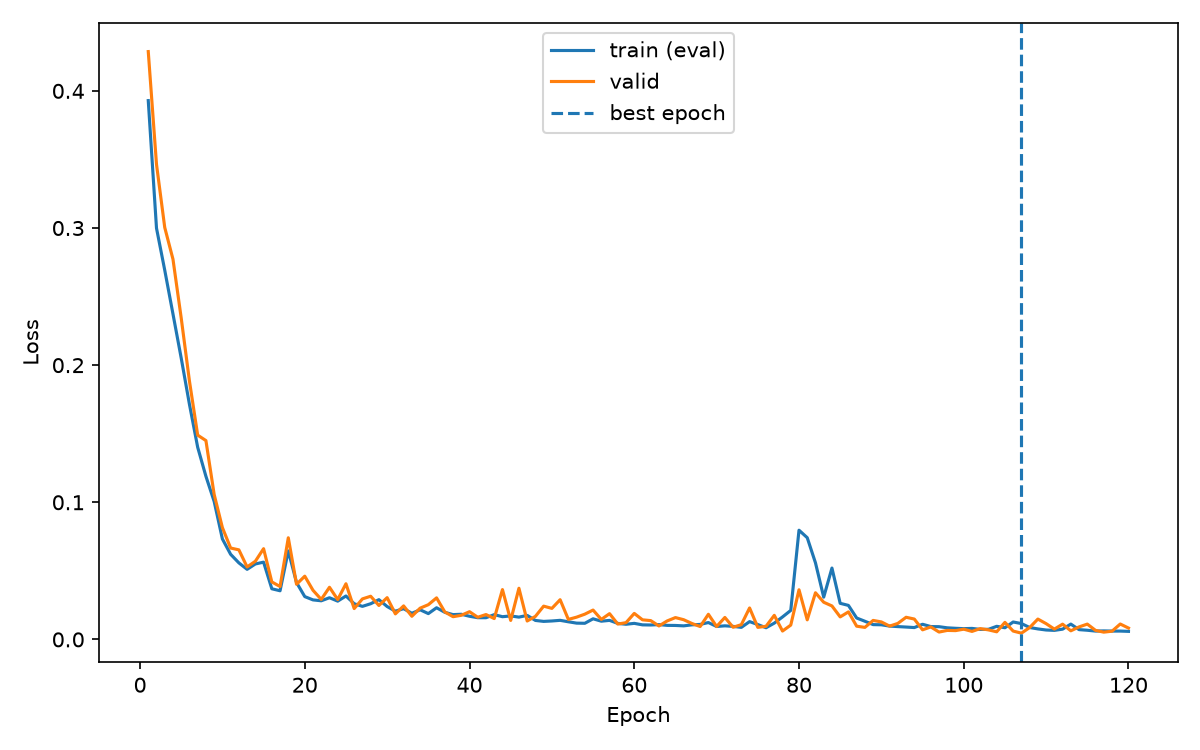

120 epochs / adamw_dropout


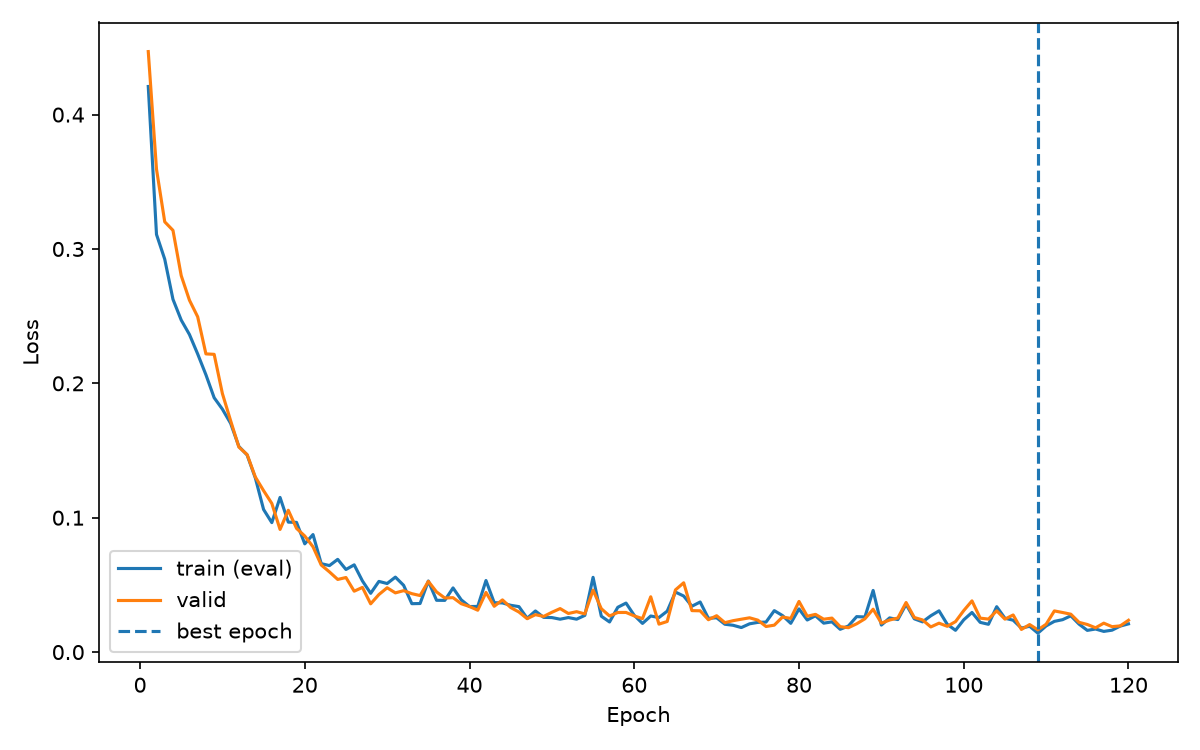

In [7]:
from IPython.display import Image, display
for result in summary.itertuples():
    print(f"{result.epochs} epochs / {result.name}")
    display(Image(filename=str(out / f"07_{result.epochs}" / f"07_{result.name}_curves.png")))


## 8. 저장 결과와 한계
각 파일은 `outputs/07_{40,80,120}/`에 저장합니다. 통합 비교표는 `outputs/07_epoch_comparison.csv`입니다.
- `07_comparison.csv`: 후보별 best epoch·loss, 복원 loss·일치 여부
- `07_{후보}_history.csv`: epoch별 train_loss_eval·valid_loss·valid_acc
- `07_{후보}_class_metrics.csv`: 클래스별 label·support·correct·recall
- `07_{후보}_predictions.csv`: 검증 표본별 id·actual·predicted
- `07_{후보}_curves.png`: 학습곡선

최적 복원 후 얻은 예측으로 지표를 계산해야 저장된 결과가 최적 모델의 평가를 의미합니다. 이번 기록은 기존 실행 결과이며, 여러 seed 반복이나 최종 test 평가는 수행하지 않았습니다.


### 9. 1차 테스트에 대한 개인적 견해

기존에 제공되어 있던 epoch 40회만 진행 했을 때 adamw, adam_dropout 모두 입력, 검증값에 대한 손실률의 그래프가 도중에 끊어지는 것 처럼 관측 돼서 추가적으로 80, 120회에 대해 테스트를 진행 했습니다.

테스트 결과, 결론적으로 80 epoch(adamw)에 대한 모델이 가장 이상적인 그래프라고 판단 했습니다.

80, 120회 모두 adamw가 진동수가 낮아 dropout이 적용되지 않은 모델로 1차로 선별을 진행했습니다.
이후 80회, 120회를 비교 했을 때 80회 진행 했을 때의 모델이 120회에 비해 진동수가 적었다는 것을 확인했습니다.
물론 80회에도 중간에 손실률이 튀는 구간이 있었지만, 120회를 진행 했을 때에 비해 상대적으로 적게 튀는 것을 확인했으며, 40회에 비해 그래프가 더욱 넓은 폭으로 상세하게 확인할 수 있었고, 손실률도 40에 비해 0.006%로 낮은 수치를 보여줬습니다.
비록 120회 진행 했을 때의 손실률이 0.004%로 더 적었음을 확인할 수 있었으나, 진동수가 80회에 비해 높게 관측 됐으므로 80회로 1차로 제한을 두는 것으로 판단했습니다.

하지만 80회 진행했을 때 약 78회 시점부터 값이 급격하게 튀는 것으로 보아, 2차로 75회로 검증을 진행하는 것이 낫다고 판단했습니다.